# Language Models and Brain Predictivity

In this project, we'll explore language models' _brain predictivity_, i.e., the extent to which text representations extracted from language models (LMs) are predictive of fMRI brain responses. If you're not familiar with fMRI scans, have a look at the course Canvas (Modules > Preliminaries > fMRI_introductory_concepts.pdf).

This notebook is structured as follows:
* **Part 1** (5 points, Question 1) provides an overview of the brain data we'll be working on, as well as code to load it properly;

* **Part 2** (15 points, Questions 2 and 3) shows how to extract text representations (_embeddings_) from LMs, feeding them with the same stimuli that participants read when their brain activity was recorded;

* **Part 3** (8 points, Question 4) shows how to quantify the brain predictivity of LM embeddings. This will be accomplished by training voxel-wise encoding models (VEMs) based on Ridge regression;

* **Part 4** (12 points, Questions 5 and 6) provides an example of a probing analysis that can be conducted to determine what type of linguistic information is reflected in the most brain-predictive embeddings.

## Part 1 – Loading the Pereira Dataset (5 points)

The fMRI data we're using in this project was collected by [Pereira et al.](https://www.nature.com/articles/s41467-018-03068-4) as part of 3 different experiments.

### Content of the Pereira Dataset

**Experiment 1** Consists of:
* A _picture_ condition, where participants viewed one concept word at a time, together with an image illustrating its meaning. Concept words were 180 in total. Each concept word was presented 6 times, each with a different image;
* A _sentence_ condition, where participants read sentences containing the same  180 concept words as the picture condition. Each concept appeared within 6 different sentences;
* A _word-cloud_ condition, which isn't relevant to this project.

The purpose of this data collection schema was to obtain brain representations at the _concept_ level, while providing _context_ (visual or sentential) to ensure participants were focusing on the intended meaning of the concept words. The concept-level responses are therefore averaged across the 6 contexts (6 pictures or 6 sentences) in both conditions (i.e., there is one brain response per concept in the picture condition and one per concept in the sentence condition).

**Experiment 2** Participants read a set of 96 text passages, each consisting of 4 sentences about a particular concept, spanning 24 topics. The publicly available data contains annotations about those topics, as well as brain responses both at the sentence and at the passage level.

**Experiment 3** Participants read 72 text passages, each consisting of 3 or 4 sentences about a particular concept. Concepts, again, spanned 24 topics.

Each passage—presented one sentence
at a time—was seen 3 times by all participants.

### Accessing the Pereira Dataset

fMRI responses from the Pereira dataset can be accessed from two sources:
1. A GG Drive [folder](https://drive.google.com/drive/folders/1MjFOyJ9zYwec2bJqL4eNXO4Mlilt0oP8);
2. [This website](https://web.mit.edu/evlab/sites/default/files/documents/index2.html).


In this notebook, we'll access the data from GG Drive. However, note that when working in Snellius, it is more convenient to download the data from the website (more on this below).

To access the data from GG Drive, complete the following steps:
1. Go to [this link](https://drive.google.com/drive/folders/1MjFOyJ9zYwec2bJqL4eNXO4Mlilt0oP8);
2. Select the folder containing data from one of the participants (in this notebook, we'll consider participant `M2`);
3.  Click on the three vertical dots > manage > add shortcut.

Note that not all participants took part in all 3 experiments. [Here](https://web.mit.edu/evlab/sites/default/files/documents/index2.html) you can check which experiment each participant completed.


Whether you downloaded the compressed data in one way or the other, you'll need to unzip it by running the following command. Make sure to add the correct path to your GG Drive. You may also need to "mount" GG Drive beforehand. This can be done by clicking on the folder icon 📁 on the left and then on the other GG Drive folder icon. You can then use the panel to navigate directly to the location of your local shortcut and copy the path after clicking on the three vertical dots.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
# ⚠️ Make sure you replace the path here with yours!
! tar -xf 'pereira_dataset/M02/data_384sentences.mat'


tar: This does not look like a tar archive
tar: Skipping to next header
tar: Exiting with failure status due to previous errors


With the `ls` command (or by using the left-hand pane 📁) we can check what's inside the folder we've just unzipped.

In [ ]:
! ls M02

data_180concepts_pictures.mat	 examples_180concepts_pictures.mat
data_180concepts_sentences.mat	 examples_180concepts_sentences.mat
data_180concepts_wordclouds.mat  examples_180concepts_wordclouds.mat
data_243sentences.mat		 examples_243sentences.mat
data_384sentences.mat		 examples_384sentences.mat


How does this map to the three experiments?

* `data_180concepts_pictures.mat`, `data_180concepts_sentenced.mat` and `data_180concepts_wordclouds.mat` contain data for Experiment 1;

* `data_384sentences.mat` contains data for Experiment 2;

* `data_243sentences.mat` contains data for Experiment 3.

For the moment, we'll focus on data from Experiment 2. We can load it as follows.

In [6]:
import numpy as np
from scipy.io import loadmat
from pprint import pprint

Conveniently, `scipy` has the `loadmat` function to load MATLAB (`.mat`) files.

In [7]:
data = loadmat('pereira_dataset/M02/data_384sentences.mat', simplify_cells=True)
data.keys()

dict_keys(['__header__', '__version__', '__globals__', 'labels_task', 'labelsPassages', 'keyPassages', 'mappingOfPassageToSentences', 'mappingOfPassageToCategory', 'labelsPassageForEachSentence', 'keyPassageCategory', 'labelsPassageCategory', 'labelsSentences', 'keySentences', 'meta', 'examples_task', 'tstats_task', 'examples_passages', 'examples_passagesentences', '__function_workspace__'])

As mentioned above, brain responses are available either at the sentence or passage level, with the passage-level responses being an average of the responses to the sentences making up the passage.

* `data['examples_passages']` stores responses at the passage level;

* `data['examples_passagesentences']` stores responses at the sentence level.

Let's start by looking at the responses at the sentence level.

In [3]:
print(f"Shape of examples_passagesentences: {data['examples_passagesentences'].shape}")

Shape of examples_passagesentences: (384, 170712)


What do these numbers represent?

* 384 is the number of sentences from Experiment 2;
* 170712 is the number of brain voxels* recorded.

However, we're not interested in all voxels — we should isolate the ones from the left-hemisphere (LH) language network. We can do so by taking advantage of the information stored in `data['meta']`, which will allow us to perform the following operations:

1. Map the brain network we're interested in to a number of specific regions of interest (ROIs)
2. Map the ROIs to specific column indexes that we can use to slice the `data['examples_passagesentences']` or the `data['examples_passages']` arrays.

Let's start from 1. fMRI data was recorded in multiple functionally-localised brain networks, which we can see listed below.

<sup><sub>*Voxels are small 3D units of brain volume — they're basically the 'pixels' making up the brain image.</sub></sup>


In [4]:
data['meta'].keys()

dict_keys(['dimx', 'dimy', 'dimz', 'dimensions', 'indicesIn3D', 'colToCoord', 'coordToCol', 'voxelsToNeighbours', 'numberOfNeighbours', 'roiIDs', 'nrois', 'roiColumns', 'nVoxels', 'nvoxels', 'atlases', 'rois', 'roiMultimask'])

In [5]:
print(data['meta']['atlases'])
data['meta']['atlases'].shape

['aal_1ofN' 'languageParcelsConservative_aal' 'languageParcels_aal'
 'semantic_aal' 'multipleDemand_aal' 'MD' 'DMN' 'languageLH' 'languageRH'
 'visual_body' 'visual_face' 'visual_object' 'visual_scene' 'visual'
 'gordon']


(15,)

In [27]:
print(data['meta']['rois'])

[array(['Precentral_L', 'Precentral_R', 'Frontal_Sup_L', 'Frontal_Sup_R',
        'Frontal_Sup_Orb_L', 'Frontal_Sup_Orb_R', 'Frontal_Mid_L',
        'Frontal_Mid_R', 'Frontal_Mid_Orb_L', 'Frontal_Mid_Orb_R',
        'Frontal_Inf_Oper_L', 'Frontal_Inf_Oper_R', 'Frontal_Inf_Tri_L',
        'Frontal_Inf_Tri_R', 'Frontal_Inf_Orb_L', 'Frontal_Inf_Orb_R',
        'Rolandic_Oper_L', 'Rolandic_Oper_R', 'Supp_Motor_Area_L',
        'Supp_Motor_Area_R', 'Olfactory_L', 'Olfactory_R',
        'Frontal_Sup_Medial_L', 'Frontal_Sup_Medial_R',
        'Frontal_Med_Orb_L', 'Frontal_Med_Orb_R', 'Rectus_L', 'Rectus_R',
        'Insula_L', 'Insula_R', 'Cingulum_Ant_L', 'Cingulum_Ant_R',
        'Cingulum_Mid_L', 'Cingulum_Mid_R', 'Cingulum_Post_L',
        'Cingulum_Post_R', 'Hippocampus_L', 'Hippocampus_R',
        'ParaHippocampal_L', 'ParaHippocampal_R', 'Amygdala_L',
        'Amygdala_R', 'Calcarine_L', 'Calcarine_R', 'Cuneus_L', 'Cuneus_R',
        'Lingual_L', 'Lingual_R', 'Occipital_Sup_L', 'Occipi

Each network corresponds to fMRI recordings from multiple sub-ROIs (listed in `data['meta']['rois']`). If we want to know which ROIs correspond to `languageLH`, which is the 8th network in the list, we can look at the 8th array of ROIs.

In [3]:
target_index = np.where(data['meta']['atlases']=='languageLH')[0].item()
print(f"Target index: {target_index}")
data['meta']['rois'][target_index]

Target index: 7


array(['L_PostTemp', 'L_AntTemp', 'L_AngG', 'L_IFG', 'L_MFG', 'L_IFGorb'],
      dtype=object)

In [4]:
target_index2 = np.where(data['meta']['atlases']=='visual_face')[0].item()
print(f"Target index: {target_index2}")
data['meta']['rois'][target_index2]

Target index: 10


array(['R_STS', 'R_FFA', 'L_FFA', 'R_OFA', 'L_STS', 'L_OFA'], dtype=object)

We can use the same index to identify the arrays of columns corresponding to the sub-ROIs in `languageLH`.

In [7]:
data['meta']['roiColumns'].shape

(15,)

In [8]:
data['meta']['roiColumns'][target_index].shape

(6,)

Great, now we can put all these arrays together into a single array of column indexes.

⚠️ Note that we have to subtract 1 to the original indexes to account for a mismatch between Python's and Matlab's indexing conventions.

In [5]:
column_indexes = np.concat([ind-1 for ind in data['meta']['roiColumns'][target_index]], axis=0)
column_indexes.shape

(4930,)

In [6]:
print(f"Column indexes for the languageLH network: {column_indexes}")

Column indexes for the languageLH network: [36304 36305 36370 ... 97596 97646 97647]


Let's now use these indexes to slice our original array of fMRI responses.

In [16]:
print(data['examples_passagesentences'].shape)
print(data['examples_passagesentences'][:, column_indexes].shape)

(384, 170712)
(384, 4930)


Last, let's see how to access the original sentences/passages, so that we know what stimulus elicited each brain response.

In [12]:
data['keySentences'].shape

(384,)

In [13]:
print(data['keySentences'][:3])

['An accordion is a portable musical instrument with two keyboards.'
 'One keyboard is used for individual notes, the other for chords.'
 'Accordions produce sound with bellows that blow air through reeds.']


In [14]:
print(data['examples_passagesentences'].shape)
print(data['examples_passages'].shape)

(384, 170712)
(96, 170712)


`data['keySentences']` contains an ordered list of all the sentences presented to participants. By combining this information with that stored in `data['labelsPassageForEachSentence']`, it is also possible to understand which sentences belong to each passage.

In [17]:
# see what this array looks like
print(data['labelsPassageForEachSentence'][:10]) # this stores to which passage each sentence belongs

# print sentences from passage 5
pprint(f"Passage 5:\n{' '.join(data['keySentences'][data['labelsPassageForEachSentence']==5])}")


[1 1 1 1 2 2 2 2 3 3]
('Passage 5:\n'
 'An automobile, or car, is a wheeled vehicle for transporting passengers. A '
 'car can be powered by a gasoline or electric engine. The driver steers the '
 'car on roads, other passengers just sit. Automobiles vary in size, number of '
 'doors and the type of trunk.')


It is also possible to map passages to topics. The list of topics is provided in:

In [18]:
# these are the available categories to which the passsages belong
data['keyPassageCategory'].shape

(24,)

In [19]:
data['labelsPassages']

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34,
       35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51,
       52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68,
       69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85,
       86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96], dtype=uint8)

The following array allows us to determine which passages correspond to which topic.

⚠️ Note the Matlab indexing starting from 1.

In [20]:
data['labelsPassageCategory'].shape

(96,)

In [21]:
data['labelsPassageCategory']

array([18, 10, 12,  7, 23, 24, 12, 13, 15, 23, 20,  2, 14, 22, 15, 20,  1,
       13, 18, 11,  9, 17, 13,  5,  6,  7,  8,  3,  8,  1,  4, 19,  4,  8,
        5,  4, 17, 16, 16, 14,  6, 21, 24,  1, 19, 10, 10, 16, 22, 22, 19,
       10, 14,  9, 15, 17,  4, 16,  7,  9,  3, 12, 18, 11, 12,  3,  2, 24,
       11, 21, 20, 21, 21, 11, 23,  6, 20, 24, 15, 17,  6, 13,  2,  7,  2,
       22, 23, 19,  8, 18,  3,  5,  9,  1,  5, 14], dtype=uint8)

We now have all the elements to work on the brain data. Below, we put them together in a class that allows you to easily access the brain data for one experiment and one participant.

Note that the fMRI responses are sometimes referred to as 'betas' below. This is because we're not working with raw brain responses, but with estimates obtained through a preprocessing method. In a nutshell, the preprocessing method estimates brain responses as the coefficients (betas) of a linear function.

In [8]:
class Experiment2Data:
    """
    Provides structured access to fMRI experiment data containing brain
    responses (betas) to sentence and passage stimuli, along with metadata
    about brain networks, topics, and stimulus labels.

    Attributes
    ----------
    betas : dict
        Beta (activation) arrays keyed by stimulus type:
        - 'sentence': betas for individual sentences
        - 'passage' : betas for full passages
    networks : np.ndarray
        Array of atlas/network names from the experiment metadata.
    experiment_data : dict
        The full raw experiment data dictionary.
    sentences : np.ndarray
        Array of all individual sentences used as stimuli.
    topics : list
        Ordered list of passage topic/category labels.
    """

    def __init__(self, experiment_data):
        """
        Parameters
        ----------
        experiment_data : dict
            Raw data dictionary expected to contain:
            - 'examples_passagesentences' : betas for sentence-level stimuli
            - 'examples_passages'         : betas for passage-level stimuli
            - 'meta'                      : dict with 'atlases' and 'roiColumns'
            - 'keySentences'              : array of sentence strings
            - 'keyPassageCategory'        : array of topic/category labels
        """
        self.betas = {
            'sentence': experiment_data['examples_passagesentences'],
            'passage':  experiment_data['examples_passages'],
        }
        # rois like languageRH
        self.networks = experiment_data['meta']['atlases']
        # data
        self.experiment_data = experiment_data
        # sentences
        self.sentences = experiment_data['keySentences']
        # passages with category mask
        self.topics = experiment_data['keyPassageCategory'].tolist()

    def get_roi_mask(self, network, stimulus_type):
        """
        Return the column indices corresponding to a given brain network (ROI).

        Looks up the network by name, then concatenates all column index arrays
        for that network's ROI, offset by -1 to convert to 0-based indexing.

        Parameters
        ----------
        network : str
            Name of the brain network/atlas to look up (must exist in self.networks).
        stimulus_type : str
            Stimulus type ('sentence' or 'passage'). Currently used for context
            but does not affect the index computation.

        Returns
        -------
        np.ndarray
            1-D array of 0-based column indices for the requested ROI.
        """
        # Find the position of the requested network in the atlas list
        target_index = np.where(self.networks == network)[0].item()

        # Concatenate ROI column ranges, converting from 1-based to 0-based indexing
        column_indexes = np.concat(
            [ind - 1 for ind in self.experiment_data['meta']['roiColumns'][target_index]],
            axis=0,
        )
        return column_indexes

    def get_passage(self, passage_id):
        """
        Reconstruct the full text of a passage by joining its sentences.

        Parameters
        ----------
        passage_id : int
            The numeric ID of the passage to retrieve.

        Returns
        -------
        str
            The passage text as a single space-joined string.
        """
        # Select all sentences that belong to the given passage
        sentences = self.sentences[
            self.experiment_data['labelsPassageForEachSentence'] == passage_id
        ]
        return ' '.join(sentences)

    def get_topic_list(self, stimulus_type):
        """
        Return a topic/category label for every stimulus of the given type.

        For passages, returns the category label array directly.
        For sentences, maps each sentence to the category of its parent passage.

        Parameters
        ----------
        stimulus_type : str
            Either 'passage' (one label per passage) or 'sentence'
            (one label per sentence).

        Returns
        -------
        np.ndarray of int
            Integer category labels aligned with the stimuli of the given type.
        """
        if stimulus_type == 'passage':
            return self.experiment_data['labelsPassageCategory']

        elif stimulus_type == 'sentence':
            categories = np.unique(
                self.experiment_data['labelsPassageCategory'].astype(int)
            )
            topic_vec = np.empty(len(self.sentences))

            for category in categories:
                # Find all passage IDs that belong to this category (1-based)
                relevant_passages = (
                    np.where(self.experiment_data['labelsPassageCategory'] == category)[0] + 1
                )
                # Assign the category label to every sentence from those passages
                for passage_id in relevant_passages:
                    topic_vec[
                        self.experiment_data['labelsPassageForEachSentence'] == passage_id
                    ] = category

            return topic_vec.astype(int)


    def get_topic_mask(self, topic, stimulus_type):
        """
        Return the indices of all stimuli belonging to a given topic.

        Parameters
        ----------
        topic : str
            Topic name as it appears in self.topics (e.g. 'science').
        stimulus_type : str
            Either 'passage' (returns passage indices) or 'sentence'
            (returns sentence indices).

        Returns
        -------
        np.ndarray or list of int
        
            - 'passage' : 1-based array of passage IDs for the topic.
            - 'sentence': list of 0-based sentence indices whose parent
              passage belongs to the topic.
        """
        # Convert topic name to its 1-based category ID
        target_topic_id = self.topics.index(topic) + 1

        # Find all passages assigned to this category (1-based IDs)
        relevant_passages = (
            np.where(self.experiment_data['labelsPassageCategory'] == target_topic_id)[0] + 1
        )

        if stimulus_type == 'passage':
            return relevant_passages
        elif stimulus_type == 'sentence':
            # Return 0-based sentence indices whose passage ID is in the relevant set
            return [
                i for i, ind in enumerate(self.experiment_data['labelsPassageForEachSentence'])
                if ind in relevant_passages
            ]

    # NOTE: here we are extending the class, adding a function to get topic labels
    def get_topic_name(self, indices, stimulus_type):
        """
        Return an array with the names of the topic belonging 
        to the sentences or passages of given indices

        Parameters
        ----------
        indices : nd.arrray
            indices of sentences/topics for which the topic name is searched (e.g. 'science').
        stimulus_type : str
            Either 'passage' (returns passage indices) or 'sentence'
            (returns sentence indices).

        Returns
        -------
        np.ndarray 
        
            - 'passage' : list of topic names belonging to the given passages
            - 'sentence': list of topic names belonging to the given sentences
        """        

        key_passages = exp.experiment_data['keyPassages']
        labels_sentence_passages = self.experiment_data['labelsPassageForEachSentence']
        topic_names = []
        if stimulus_type == 'sentence':
            indices = labels_sentence_passages[indices]

        for ind in indices:
            topic_names.append(key_passages[ind-1])

        return topic_names


See how we can use our class to access the data conveniently.

In [9]:
exp = Experiment2Data(data)

# see (some of) the sentences
exp.sentences[:5]

array(['An accordion is a portable musical instrument with two keyboards.',
       'One keyboard is used for individual notes, the other for chords.',
       'Accordions produce sound with bellows that blow air through reeds.',
       'An accordionist plays both keyboards while opening and closing the bellows.',
       'An apartment is a self-contained home that is part of a building.'],
      dtype=object)

In [24]:
exp.betas['passage'].shape

(96, 170712)

In [25]:
exp.networks

array(['aal_1ofN', 'languageParcelsConservative_aal',
       'languageParcels_aal', 'semantic_aal', 'multipleDemand_aal', 'MD',
       'DMN', 'languageLH', 'languageRH', 'visual_body', 'visual_face',
       'visual_object', 'visual_scene', 'visual', 'gordon'], dtype=object)

**QUESTION 1** (5 points)

Now use the class provided above to do the following:

a. Select betas from the `'languageLH'` network, at the passage level (1 pt);

b. Get the sentences from passage 2 (1 pt);

c. Get sentences and passages from the topic `'animal'` (2 pt);

d. Get sentence-level brain responses from the topic `'animal'` (1 pt).

In [43]:
# Q1a
# select betas form languageLH at the passage level
languageLH_indices = exp.get_roi_mask('languageLH', 'passage')
# slice the betas and print their shape
languageLH_betas = exp.betas['passage'][:,languageLH_indices]
# print the shape of your matrix of masked betas
print(f"Shape of beta matrix at passage level for languageLH ROIs: {languageLH_betas.shape}")

Shape of beta matrix at passage level for languageLH ROIs: (96, 4930)


In [11]:
# Q1b
# print the sentences from passage 2
passage = exp.get_passage(2)
print(passage)

An apartment is a self-contained home that is part of a building. An apartment may have one or more rooms, as well as a kitchen and a bathroom. Some apartments are for single people, others for families. The building can have a garage, a laundry facility or extra storage space.


In [15]:
# Q1b
# print sentences from the topic 'animal'
indices = exp.get_topic_mask('animal', 'passage')
for i in indices:
  print(exp.get_passage(i))

Cats are small furry animals with four legs and a tail. Cats like to groom themselves by licking their fur. Cats can hunt mice or birds, but are often fed by their owners. The claws of cats are retractable so that they keep sharp.
Elephants are the largest kind of land mammal, weighing several tons. An elephant has a long nose called a trunk, which can grab things or food. The elephant has a pair of ivory tusks, for moving objects or digging into trees. The elephant flaps its large ears to cool the blood in them and its body.
A horse is a large hoofed mammal with four long, muscular legs. A horse has a tail and a mane on its neck, and is usually gray or brown. Horses have been used for draft work, travel and entertainment. A human can ride a horse while it walks, trots or gallops.
A whale is a very large mammal that lives in the ocean. Whales breathe through blowholes on their heads when surfacing. The blubber in a whale serves as an energy reservoir and as insulation. Whales have been

In [16]:
# Q1c
# print the passages from the topic 'animal'
key_passage = exp.experiment_data['keyPassages']
for j in indices:
  print(key_passage[j-1])

Cat
Elephant
Horse
Whale


Here we show and alternative solution that uses a function we added to the class.

In [17]:
print(exp.get_topic_name(indices, 'passage'))

['Cat', 'Elephant', 'Horse', 'Whale']


In [34]:
# Q1d
# get sentence-level betas first
languageLH_betas = exp.betas['sentence']
#obtain the topic mask
mask = exp.get_topic_mask('animal', 'sentence')

# slice the betas and print their shape
animal_languageLH_betas = languageLH_betas[mask,:]

print(f"Shape of betas for the sentences of topic animal: {animal_languageLH_betas.shape}")

Shape of betas for the sentences of topic animal: (16, 170712)


The code above should provide a good starting point to work on the brain data. One more thing before moving to the next part concerns downloading the data on Snellius.

This can be done by completing the following steps:
1. Go to [this](https://web.mit.edu/evlab/sites/default/files/documents/index2.html) webpage;
2. Place your cursor on the link for one participant (e.g., M2), right-click, and copy the link;
3. Paste the link within the following command `! wget -O M02.tar "PASTE YOUR LINK HERE"`; of course, if you're downloading the data from a participant different from M02, the name of the `M02.tar` folder should be changed to reflect that;
4. Run it in the command line (the exact command for participant M2, for example, is `! wget -O M02.tar "https://www.dropbox.com/s/n5yfb2cupd9zmwk/M02.tar?dl=1"`).


The folder will then need to be unzipped with the same command we used above.



## Part 2 – Extracting Text Representations from Language Models (15 points)

In this Part, we'll look at how to extract text representations from LMs, feeding them with the same input stimuli that participants from the Pereira experiments were presented with.

First, let's see where suitable LMs can be found. Most modern LMs are available on 🤗 HuggingFace. You can think of it as a platform hosting 🔥PyTorch-implemented LMs that can be accessed in a 'standard' way. Just like `sklearn` provides ML algorithms with standard methods — e.g., `fit`, `predict`, `fit_transform` — HF hosts models that can be loaded, trained, and used for inference in a standard way with the `transformers` library. What this means concretely will become clearer in the following.

⚠️ This Part of the notebook needs a GPU to run correctly, so make sure you go to Runtime > Change Runtime Type, and select a 'T4 GPU'. Restarting the runtime also causes all variables to be lost, so we'll need to re-import all the libraries and variables.

In [1]:
import numpy as np
from transformers import AutoModel, AutoTokenizer
import torch

/gpfs/home1/scur0583/MLLM_Project/project2/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

If the runtime has been selected correctly, the output of the cell above should be `device(type='cuda')`. If the output looks like `device(type='cpu')` instead, it means that we're not using a GPU and the runtime should be changed.

Now, let's see how we can load an LM using the `transformers` library. In this example, we're going to use [BERT](https://aclanthology.org/N19-1423/), a real NLP classic.

In [4]:
tokenizer = AutoTokenizer.from_pretrained("google-bert/bert-base-uncased")
model = AutoModel.from_pretrained("google-bert/bert-base-uncased", device_map = device)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 372.60it/s]
[transformers] BertModel LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [5]:
model.config

BertConfig {
  "add_cross_attention": false,
  "architectures": [
    "BertForMaskedLM"
  ],
  "attention_probs_dropout_prob": 0.1,
  "bos_token_id": null,
  "classifier_dropout": null,
  "dtype": "float32",
  "eos_token_id": null,
  "gradient_checkpointing": false,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.1,
  "hidden_size": 768,
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "is_decoder": false,
  "layer_norm_eps": 1e-12,
  "max_position_embeddings": 512,
  "model_type": "bert",
  "num_attention_heads": 12,
  "num_hidden_layers": 12,
  "pad_token_id": 0,
  "position_embedding_type": "absolute",
  "tie_word_embeddings": true,
  "transformers_version": "5.20.1",
  "type_vocab_size": 2,
  "use_cache": true,
  "vocab_size": 30522
}

In [ ]:
model.config.max_position_embeddings

512

Most LMs available on the `transformer` library can be loaded this way. `AutoTokenizer` and `AutoModel` automatically import the correct tokenizer and LM based on the configuration file for the target model, which we have specified as `google-bert/bert-base-uncased`.

There are many more different models available on 🤗HF. [Here](https://huggingface.co/models) you can look for a specific architecture and see if it's available.

⚠️ When you load a pretrained model, its weights need to be downloaded on your machine. If you work on Colab, the weights end up in a 'temporary' folder that gets automatically erased when your runtime disconnects. However, if you work locally or on Snellius, the weights will end up taking space in the HF cache. Concretely, this means that if you try to load many large models, you'll run out of storage space very quickly.

To avoid this, Snellius provides a **scratch space**, i.e., a space specifically intended to temporarily store model weights or datasets so that they don't take up your own space. Everything on the scratch space gets deleted at regular intervals, so you don't have to worry about deleting your model weights when you don't need them anymore.

How can you make sure model weights are downloaded in this scratch space, then? Just add the following (uncommented) lines to jour job script (or notebook) and pass `cache_dir='/scratch-shared/[YOUR_USER_NAME]/hf_dir/'` as an additional argument to `.from_pretrained()` when you define the model and the tokenizer.

In [ ]:
# ⚠️ replace with your own Snellius user name!
# ! export HF_HOME='/scratch-shared/[YOUR_USER_NAME]/hf_dir/'
# ! export HF_HUB_CACHE='/scratch-shared/[YOUR_USER_NAME]/hf_dir/'

Ok, now let's see how we can get model representations for an example sentence.

In [11]:
my_sentence = "Roses are red, violets are blue\nI should get sentence representations\nbut I don't have a clue."
print(my_sentence)

Roses are red, violets are blue
I should get sentence representations
but I don't have a clue.


First, we have to tokenise the sentence. We can do so with the tokenizer we have defined.

Note that, in this example, we are passing only one sentence as a string. However, we normally want to tokenise multiple sentences in one pass. This can be achieved by passing a list of sentences.

In [12]:
# we have a maximal length of sentences that a model can process
# we can add meaningless tokens to the end of sentences to make sure all are of the same length
# attention masks make sure that the model is only taking care of useful tokens
# token types are either the sentence itself or possible continuations that the model has to predict (0 or 1)
inputs = tokenizer(my_sentence, padding=True, truncation=True, return_tensors="pt", return_offsets_mapping=True)
inputs

{'input_ids': tensor([[  101, 10529,  2024,  2417,  1010,  8766,  2015,  2024,  2630,  1045,
          2323,  2131,  6251, 15066,  2021,  1045,  2123,  1005,  1056,  2031,
          1037,  9789,  1012,   102]]), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]]), 'offset_mapping': tensor([[[ 0,  0],
         [ 0,  5],
         [ 6,  9],
         [10, 13],
         [13, 14],
         [15, 21],
         [21, 22],
         [23, 26],
         [27, 31],
         [32, 33],
         [34, 40],
         [41, 44],
         [45, 53],
         [54, 69],
         [70, 73],
         [74, 75],
         [76, 79],
         [79, 80],
         [80, 81],
         [82, 86],
         [87, 88],
         [89, 93],
         [93, 94],
         [ 0,  0]]])}

In [ ]:
inputs['offset_mapping'].size()

torch.Size([1, 24, 2])

In [ ]:
mapping = inputs['offset_mapping'].detach().numpy().squeeze()

In [ ]:
for idxs in mapping:
  print(my_sentence[idxs[0]: idxs[1]])


Roses
are
red
,
violet
s
are
blue
I
should
get
sentence
representations
but
I
don
'
t
have
a
clue
.



In [ ]:
inputs2 = tokenizer([my_sentence, 'Hello'], padding=True, truncation=True, return_tensors="pt")
inputs2

{'input_ids': tensor([[  101, 10529,  2024,  2417,  1010,  8766,  2015,  2024,  2630,  1045,
          2323,  2131,  6251, 15066,  2021,  1045,  2123,  1005,  1056,  2031,
          1037,  9789,  1012,   102],
        [  101,  7592,   102,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0]]), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]])}

The tokenizer outputs an object with the following keys:

* `'input_ids'` are indexes on the model's token vocabulary;
* `'token_type_ids'` are identifiers used to distinguish between different input types (e.g., questions vs. answers). We don't particularly care about them in our use-case;
* `'attention_mask'` is a binary mask containing ones where there are 'valid' tokes the model should 'attend to' and zeros elsewhere. Here, we only have ones because we've passed a sentence. However, when passing multiple sentences/texts, the tokeniser would have to pad the input, and padding tokens would be assigned a '0' on the attention mask.



Now, we'll pass the `inputs` to the model to get representations.

In [ ]:
with torch.no_grad():
    embeddings = model(**inputs.to(device), return_dict=True)

Great, now let's see what we've obtained.

In [ ]:
embeddings.keys()

odict_keys(['last_hidden_state', 'pooler_output'])

The representations we care about are in `last_hidden_state`. As the name suggests, these are the hidden states from the last model layer.

In [ ]:
# 768 is the dimensionality of the data when processing ??
embeddings['last_hidden_state'].size()

torch.Size([1, 24, 768])

Let's unpack the dimensionality of this output.

* 1 is the number of 'texts' we've embedded (in our case, one sentence);
* 24 is the number of tokens;
* 768 is the dimensionality of token embeddings, as per model configuration.

Ideally, we want one embedding per sentence, but here we've got 24. How do we slice/aggregate them? In other words, which *pooling strategy* do we employ? There are several options:

* select only the _CLS token_ (first token). This makes a lot of sense for BERT, because its pretraining 'encourages' the CLS token to learn a sort of 'global representation' for a sentence;

* select only the _last token_. This is a common choice when working with autoregressive LMs. The underlying intuition is that the last token of a sequence contains information about all the preceding tokens and, therefore, the whole sentence/text;

* compute an _average_ over tokens. Another common strategy used across different types of models.

Here, since we're working with BERT, we'll select only the CLS token. We can also convert the tensors to numpy, which is useful in case we then want to save our embeddings.

In [ ]:
pooled_embeddings = embeddings['last_hidden_state'].cpu().numpy()[:, 0, :]
print(f"Shape of the pooled embeddings: {pooled_embeddings.shape}")

(1, 768)

**QUESTION 2** (6 points)

Alright, we have our embedding for the example sentence. Now, try to get the _layer-wise_ embeddings for all sentences from experiment 2 (the ones we used in the first part of the notebook). Concretely, you'll have to perform the following steps:

a. Re-download/re-load the data from one participant (all the variables were lost when we changed the runtime type) and get the sentence stimuli. You can either access them from the data dict directly or use the `Experiment2Data` class provided at the end of Part1 (1 pt);

b. Extract the embeddings from _all_ BERT layers, not only the last one. This is because representations from LMs' last layer are rarely the most brain predictive. You can get have the model output hidden states from all layers by passing `output_hidden_states=True` (2 pt);

c. Turn the outputs into numpy embeddings and stack them appropriately. The shape of your resulting embeddings should be (n_layers, n_sentences, 768) (2 pt);

d. Use `np.save()` to save your embeddings somewhere on GG Drive (or Snellius). They'll be useful in Part 3 of this notebook (1 pt).

In [13]:
# Q2a
from scipy.io import loadmat

# Reload data from one participant, for clarity we redifine exp
data = loadmat('pereira_dataset/M02/data_384sentences.mat', simplify_cells=True)
exp = Experiment2Data(data)
participant_data = exp.betas['sentence']
# Obtain list of sentences
sentences = exp.sentences
sentences = sentences.tolist()

In [14]:
# Q2b

# Tokenize the sentences for use as inputs
input = tokenizer(sentences, padding=True, truncation=True, return_tensors="pt")
# Pass inputs to model and obtain hidden states for all inputs
with torch.no_grad():
  embeddings = model(**input.to(device), return_dict = True, output_hidden_states=True)

In [19]:
hidden_states = embeddings['hidden_states']

In [20]:
# Q2c

# Initialise an empty numpy array for the pooled embeddings
pooled_embedding_array = np.empty((len(hidden_states), len(sentences), 768))
# For each layer in the model, insert the pooled embeddings into the numpy array
for i in range(13):
  cls_selected = hidden_states[i].cpu().numpy()[:, 0, :]
  pooled_embedding_array[i] = cls_selected

print(f"Shape of the pooled embeddings array: {pooled_embedding_array.shape}")

Shape of the pooled embeddings array: (13, 384, 768)


In [ ]:
# Q2d
# Save the numpy array to your GG Drive or wherever you find it convenient 
np.save('/content/drive/MyDrive/pooled_embbeding_array.npy', pooled_embedding_array)

**QUESTION 3**  (9 points)

Now, try to do the same for an MPNet sentence embedder (`model_id = 'sentence-transformers/all-mpnet-base-v2'`).

More specifically, you have to:

a. Load the model and tokenizer correctly (2 pt);

b. Extract and stack sentence embeddings from the last layer, with mean pooling (4 pt);

c. Extract and stack sentence embeddings from all layers, also with mean pooling (3 pt).

⚠️ Note: When mean-pooling, make sure you discard padding tokens.

In [21]:
# Q3a
# Load Model and tokenizer
MPNet_tokenizer = AutoTokenizer.from_pretrained("sentence-transformers/all-mpnet-base-v2")
MPNet_model = AutoModel.from_pretrained("sentence-transformers/all-mpnet-base-v2", device_map = device)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 384.80it/s]


In [22]:
MPNet_model.config

MPNetConfig {
  "architectures": [
    "MPNetForMaskedLM"
  ],
  "attention_probs_dropout_prob": 0.1,
  "bos_token_id": 0,
  "dtype": "float32",
  "eos_token_id": 2,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.1,
  "hidden_size": 768,
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "layer_norm_eps": 1e-05,
  "max_position_embeddings": 514,
  "model_type": "mpnet",
  "num_attention_heads": 12,
  "num_hidden_layers": 12,
  "pad_token_id": 1,
  "relative_attention_num_buckets": 32,
  "tie_word_embeddings": true,
  "transformers_version": "5.20.1",
  "vocab_size": 30527
}

In [23]:
# Q3b
# Tokenise the sentences
MPNet_input = MPNet_tokenizer(sentences, padding=True, truncation=True, return_tensors="pt")
# Feed the model with the sentences
with torch.no_grad():
  MPNet_embeddings = MPNet_model(**MPNet_input.to(device), return_dict=True)

In [24]:
MPNet_embeddings.keys()

odict_keys(['last_hidden_state', 'pooler_output'])

In [25]:
MPNet_embeddings['last_hidden_state'].shape

torch.Size([384, 24, 768])

In [26]:
# Create an empty array to store the pooled embeddings
MPNet_last_hidden_state = MPNet_embeddings['last_hidden_state']
pooled_MPNet_embeddings = np.empty((len(sentences), MPNet_last_hidden_state.shape[2]))
# Obtain the attention masks from the inputs
MPNet_attention_masks = MPNet_input['attention_mask']
# Iterate over last-layer hidden states
for i in range(len(sentences)):
  sentence_embedding = MPNet_last_hidden_state[i]
  mask = MPNet_attention_masks[i]
  non_pad_mask = mask == 1
  # Obtain the mean-pooled embedding
  mean_embedding = torch.mean(sentence_embedding[non_pad_mask], dim=0).cpu().detach().numpy()
  # Store the pooled embedding in the dedicated array
  pooled_MPNet_embeddings[i] = mean_embedding

print(f"Shape of the pooled embeddings array: {pooled_MPNet_embeddings.shape}")

Shape of the pooled embeddings array: (384, 768)


In [27]:
# Q3c

# Feed the tokenised sentences to the model again, ensuring it returns the hidden states from all layers
all_layer_input = MPNet_tokenizer(sentences, padding=True, truncation=True, return_tensors="pt")

with torch.no_grad():
  all_layer_embeddings = MPNet_model(**all_layer_input.to(device), return_dict= True, output_hidden_states = True)

In [ ]:
all_layer_embeddings.keys()

odict_keys(['last_hidden_state', 'pooler_output', 'hidden_states'])

In [ ]:
all_layer_embeddings['hidden_states'][0].shape

torch.Size([384, 24, 768])

In [28]:
# Create an empty array to store the pooled embeddings
hidden_states = all_layer_embeddings['hidden_states']
all_layer_pooled_embeddings = np.empty((len(hidden_states), len(sentences), 768))
attention_mask = all_layer_input['attention_mask']
# Loop over the layers in the output hidden stated
for state in range(13):
  hidden_state = hidden_states[state]
  # Create a list to store pooled embeddings for this layer
  layer_pooled_embeddings = np.empty((len(sentences), 768))
  # Loop over the embeddings from current layer
  for sen in range(len(sentences)):
    sentence_embedding = hidden_state[sen]
    mask = attention_mask[sen]
    non_pad_mask = mask == 1
    # Obtain the mean-pooled embedding
    mean_embedding = torch.mean(sentence_embedding[non_pad_mask], dim=0).cpu().detach().numpy()
    # Append pooled embedding to list
    layer_pooled_embeddings[sen] = mean_embedding
  # Store layer embeddings in the 'all-layer' array
  all_layer_pooled_embeddings[state] = layer_pooled_embeddings

print(f"Shape of the pooled embeddings array: {all_layer_pooled_embeddings.shape}")

Shape of the pooled embeddings array: (13, 384, 768)


## Part 3 – Assessing Brain Predictivity (8 points)

In this part of the notebook, we'll learn how to train voxel-wise encoding models (VEMs), i.e., Ridge regressions that predict brain data from model representations.

We don't need a GPU for this, so we can switch our runtime to CPU. This means that, like above, we'll have to re-import some libraries and re-load the brain data.

In [29]:
import numpy as np
from scipy.io import loadmat
from scipy.stats import false_discovery_control
from sklearn.metrics import r2_score
from sklearn.model_selection import KFold
import matplotlib.pyplot as plt
from sklearn.linear_model import RidgeCV

Let's use the `Experiment2Data` class from Part 1 to select betas from the `languageLH` network.

In [30]:
# for overview we are redifining the class with a new name
data = loadmat('pereira_dataset/M02/data_384sentences.mat', simplify_cells=True)
stim_type = 'sentence'
mask = exp.get_roi_mask('languageLH', stim_type)
betas = exp.betas[stim_type][:, mask]

Now, let's load the BERT embeddings we saved before. For now, we'll just use last-layer embeddings.

In [31]:
# Note that we uploaded the pooled embeddings from the google drive to the Snellius project, so we are now downloading it from there.
embeddings = np.load('pooled_embbeding_array.npy')
ll_embs = embeddings[-1]

In [32]:
print(f"Shape of the embeddings array: {embeddings.shape}")
print(f"Shape of the embeddings on the last layer: {ll_embs.shape}")

Shape of the embeddings array: (13, 384, 768)
Shape of the embeddings on the last layer: (384, 768)


We can now set up Ridge regression in a 5-fold cross-validation framework. Since we don't know the optimal value for the regularisation parameter $α$ in advance, we can determine this via an inner leave-one-out cross-validation. Thankfully, `RidgeCV` takes care of this for us, so we just have to pass a range of candidate `alphas` and specify `alpha_per_target=True`. This deviates from the default option and it means that the best value for $α$ will be selected independently for each voxel. This is important when predicting fMRI responses, as every voxel may have its specific sensitivity.

In [33]:
# Set up 5-fold cross-validation
kf = KFold(n_splits=5)
kf.get_n_splits()

all_preds = []  # Collect out-of-fold predictions across all folds

for i, (train_index, test_index) in enumerate(kf.split(ll_embs)):

    # Split embeddings that correspond to the stimuli (X) and brain betas (y) into train and test sets
    x_train, x_test = ll_embs[train_index], ll_embs[test_index]
    y_train, y_test = betas[train_index], betas[test_index]

    # Fit a Ridge regression with automatic regularisation selection via cross-validation;
    # alpha_per_target=True allows a different alpha to be chosen for each output (voxel)
    ridge = RidgeCV(alphas=np.logspace(1, 20, 40), alpha_per_target=True)
    ridge.fit(x_train, y_train)

    # Predict brain activity for the held-out test sentences
    preds = ridge.predict(x_test)
    all_preds.append(preds)

# Stack fold predictions into a single array of shape (n_sentences, n_voxels),
# restoring the original sentence order
st_preds = np.vstack(all_preds)

In [34]:
print(f"Shape of the predictions array: {st_preds.shape}")

Shape of the predictions array: (384, 4930)


To do so, we can compute the $R^2$ between the predicted and the observed responses.

In [35]:
r2s = r2_score(betas, st_preds, multioutput='raw_values')
print(f"Mean R2: {r2s.mean():.3f}")
print(f"Min R2: {r2s.min():.3f}")
print(f"Max R2: {r2s.max():.3f}")

Mean R2: 0.021
Min R2: -0.164
Max R2: 0.322


As we can see, there is quite some variance in $R^2$ values. This is expected, as encoding models are often unable to predict all voxels statistically significantly. To determine in which voxels predictions are truly reliable, we can perform a permutation test.

The intuition behind this test is to re-compute the $R^2$ many times after permuting predictions. This operation 'breaks' the link between predicted and observed brain responses, allowing us to compute an $R^2$ which serves as a random baseline. By calculating $R^2$ under different permutations, we can obtain a null distribution, which is useful to compute a _p_-value.

In [36]:
num_permutations = 1000

# Pre-allocate results array: one R² value per permutation per output (voxel)
permuted_r2s = np.empty((num_permutations, betas.shape[1]))

# Fix random seed for reproducibility
np.random.seed(10)

for i in range(num_permutations):
    # Shuffle the row order of predictions, breaking the correspondence
    # between predicted and actual brain activity
    inds = np.random.choice(len(st_preds), size=len(st_preds), replace=False)

    # Compute R² for each output under the permuted (null) predictions
    perm_r2 = r2_score(betas, st_preds[inds], multioutput='raw_values')

    permuted_r2s[i] = perm_r2


In [37]:
print(f"Shape of permuted r2s: {permuted_r2s.shape}")

Shape of permuted r2s: (1000, 4930)


Now we can use these $R^2$ values as a null distribution, allowing us to calculate voxel-wise *p*-values. Concretely, the _p_-value for one voxel can be computed as the number of cases where permutation $R^2$ values are greater or equal to the observed $R^2$, divided by the total number of $R^2$ (1000 permuted $R^2$s + 1 observed $R^2$).

In [38]:
p_vals = ((permuted_r2s >= r2s).sum(axis=0) + 1) / (num_permutations + 1)

In [39]:
p_vals.shape

(4930,)

One last thing we have to do is apply a **correction for multiple comparisons**. This is a standard procedure performed when multiple statistial tests are conducted for the same experiment.

But why do we need such a correction? The motivation is as follows. If we perform one statistical test with $\alpha=0.05$, there is a 5% chance of having a false positive. However, if we perform $N$ independent statistical tests, each with $\alpha=0.05$, eventually the probability to have at least one false positive is

$P(X\ge1) = 1 - P(X=0) = 1 - (0.95)^N$

If we perform 60 statistical tests, our $P(X\ge1)$ is already $\sim 0.95$. If we perform 4030, $P(X\ge1)\sim1$ ⚠️

Corrections for multiple comparisons are intended precisely to deal with this issue. The most common corrections for multiple comparisons are the Bonferroni correction and the Benjamini-Hochberg correction, often called 'FDR' because it controlls for the family-wise error rate (false-discovery rate).

You don't need to understand in detail what these corrections are doing. Just trust that, in this case, an FDR correction is more appropriate, `scipy` provides a handy implementation.

In [ ]:
corrected_pvals = false_discovery_control(p_vals)
print(f"Significant p-values before correction: {(p_vals<0.05).sum()}")
print(f"Significant p-values after correction: {(corrected_pvals<0.05).sum()}")

Significant p-values before correction: 3296
Significant p-values after correction: 3161


We see that our correction reduced the number of _p_-values that can be considered statistically significant. We can now look at the average accuracy computed only on the significant voxels.

In [ ]:
r2_signif = r2s[corrected_pvals < 0.05].mean()
print(f"R2 on significant voxels: {r2_signif:.3f}")

R2 on significant voxels: 0.051


**QUESTION 4** (8 points)

We can see that it's a bit higher, but still not impressive. Can you identify a model layer where this value is higher? To do so, perform the following steps:

a. Fit the VEMs again across all model layers, storing predictions (2 pt);

b. Compute $R^2$ values layer-wise and plot them to identify the most brain-predictive layer (2 pt);

c. Perform a permutation test on the best layer and identify voxels that can be predicted statistically significantly. Don't forget to correct for multiple comparisons. Are significant voxels more or fewer than those we could predict significantly using last-layer representations? (4 pt)

In [ ]:
import numpy as np
from scipy.io import loadmat
from scipy.stats import false_discovery_control
from sklearn.metrics import r2_score
from sklearn.model_selection import KFold
import matplotlib.pyplot as plt
from sklearn.linear_model import RidgeCV

# to not having to rerun the whole notebook we reimport the data here
data = loadmat('pereira_dataset/M02/data_384sentences.mat', simplify_cells=True)

In [41]:
# for clarity we redifine exp and the embeddings
exp = Experiment2Data(data)
embeddings = np.load('pooled_embbeding_array.npy')

In [44]:
# Q4a
languageLH_indices = exp.get_roi_mask('languageLH', 'passage')
betas = exp.betas['sentence'][:,languageLH_indices]
# Create an empty array to store predictions for all layers
all_layer_predictions_array = np.empty((13, 384, 4930))
# Loop over embeddings layer-wise
for i in range(13):
  # Instantiate kfold with 5 splits
  kf = KFold(n_splits=5)
  kf.get_n_splits()
  # Create an empty list to store fold predictions
  this_layer_embeddings = embeddings[i]
  # Loop over folds
  
  for j, (train_index, test_index) in enumerate(kf.split(this_layer_embeddings)):
      # Obtain train and test partitions
    x_train, x_test = this_layer_embeddings[train_index], this_layer_embeddings[test_index]
    y_train, y_test = betas[train_index], betas[test_index]
    # Fit Ridge regression
    ridge = RidgeCV(alphas=np.logspace(1, 20, 40), alpha_per_target=True)
    ridge.fit(x_train, y_train)
    # Compute predictions
    preds = ridge.predict(x_test)
    # Store predictions
    # Add layer-wise predictions to prediction vector
    all_layer_predictions_array[i, test_index, :] = preds

In [45]:
print(f"Shape of the prediction array: {all_layer_predictions_array.shape}")

Shape of the prediction array: (13, 384, 4930)


Best layer: 5


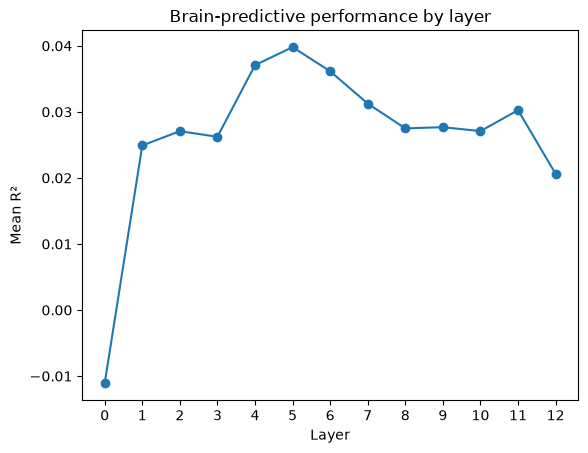

In [46]:
# Q4b
# Create an empty array to store R2s
r_squared_array = np.empty((13, 4930))
# Loop over predictions layer-wise
for i in range(13):
# Identify the best layer
  r2 = r2_score(betas, all_layer_predictions_array[i], multioutput='raw_values')
  r_squared_array[i] = r2

# compute mean values
mean_r_squared_array = np.mean(r_squared_array, axis=1)

best_layer = np.argmax(mean_r_squared_array)
print(f"Best layer: {best_layer}")

# Plot layer-wise R2s
plt.plot(range(13), mean_r_squared_array, marker='o')
plt.xlabel('Layer')
plt.ylabel('Mean R²')
plt.title('Brain-predictive performance by layer')
plt.xticks(range(13))
plt.show()

In [47]:
# Q4c
# Obtain the predictions from the best layer
best_layer_predictions = all_layer_predictions_array[best_layer]

num_permutations = 1000
# Create an empty array to store R2s obtained from the permutations
permutation_r_squared_array = np.empty((num_permutations, 4930))
# Set a random seed equal to 10
np.random.seed(10)
# Loop over permutations
for perm in range(num_permutations):
  # Obtain indexes
  indexes = np.random.choice(len(best_layer_predictions), size=len(best_layer_predictions), replace=False)
  # Compute R2
  perm_r2 = r2_score(betas, best_layer_predictions[indexes], multioutput='raw_values')
  # Store R2
  permutation_r_squared_array[perm] = perm_r2


In [48]:
# Q4c
# Obtain real R2s for the best layer
real_r2s_best_layer = r_squared_array[best_layer]
# Compute p-values
p_values = ((permutation_r_squared_array >= real_r2s_best_layer).sum(axis=0) +1) / (num_permutations+1)
# Apply correction for multiple comparisons
corrected_p_values = false_discovery_control(p_values)
# Print mean predictivity computed on significant voxels
r2_signif = real_r2s_best_layer[corrected_p_values < 0.05].mean()
print(f"R2 on significant voxels: {r2_signif:.3f}")


R2 on significant voxels: 0.064


## Part 4 – Probing the Content of Model Representations (12 points)

In this last Part, we'll try to perform a probing experiment to check what type of linguistic information is represented in the most brain-predictive layer. Is it low-level information such as sentence length or more high-level information, such as the topic of the sentence?

As an example, we can check whether information about sentence length is present — and therefore decodable — from the representations computed from layer 1.

In [49]:
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

Let's first compute length for each sentence, expressed simply as the number of words it contains.

In [50]:
lens = np.array([len(sent.split(' ')) for sent in data['keySentences']])
print(lens[:10])

[10 11 10 11 12 16  9 13 12 11]


Now we can proceed with proper probing. The idea behind linear probing is simple: if we can decode some type of imformation (feature) from the embeddings from one layer, it means that the information is _represented_ in that layer.

In when performing _linear_ probing, the decodability of a feature is operationalised as the ability of a linear model to accurately predict that feature from the embeddings.

This can be performed as shown below. Note the use of `cross_val_score` to fit and evaluate the Ridge regressions across CV folds in a very compact way.  

In [51]:
# selecting embeddings from layer 1 (layer 0 is just an embedding layer)
ll_embs = embeddings[1]

# setting up a pipeline that scales the features and fits Ridge regression,
# selecting the optimal value for the regularisation parameter
# Pipeline stacks multiple steps together
probe = Pipeline([
      ("scaler", StandardScaler()),
      ("regressor", RidgeCV(alphas=np.arange(1,10))),
  ])

In [26]:
probe

Pipeline(steps=[('scaler', StandardScaler()),
                ('regressor',
                 RidgeCV(alphas=array([1, 2, 3, 4, 5, 6, 7, 8, 9])))])

In [ ]:
# probe.fit(ll_embs, betas) 

In [28]:
# creating CV splits
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# fitting the pipeline and computing R2 scores in a compact way
r2_scores = cross_val_score(probe, ll_embs, lens, cv=cv, scoring="r2")

print(f"R² per fold : {np.round(r2_scores, 3)}")
print(f"Mean R²     : {r2_scores.mean():.3f}  ±  {r2_scores.std():.3f}")


R² per fold : [0.936 0.895 0.877 0.895 0.872]
Mean R²     : 0.895  ±  0.023


It seems like the feature is quite well-represented at layer 1.

**QUESTION 5** (4 points)

a) Did you expect that? How do you think the decodability of this feature would change across model layers? (2 pt)

We did expect it. Martha said during her lecture on BERT, that earlier layers handle lower-level tasks better and that syntacically more complex tasks are better represented in later layers of the model. Seeing as sentence length is a comparatively low-level feature of the data, higher R^2 scores are to be expected at earlier layers. We would similarly expect this value to go down as we approach the later layers of the model, when more complex tasks become better represented.


b) Now check if the most brain predictive layer is also accurately representing sentence length. Do you think length is driving brain predictivity? (2 pt)

In [52]:
# Selecting embeddings from layer 1 (layer 0 is just an embedding layer)
best_layer_embeddings = embeddings[best_layer]
# Setting up a pipeline that scales the features and fits Ridge regression,

# selecting the optimal value for the regularisation parameter
probe2 = Pipeline([
      ("scaler", StandardScaler()),
      ("regressor", RidgeCV(alphas=np.arange(1,10))),
])


# Create CV splits
cv = KFold(n_splits=5, shuffle=True, random_state=42)
# Fit the pipeline and compute R2 scores in a compact way
other_r2_scores = cross_val_score(probe2, best_layer_embeddings, lens, cv=cv, scoring="r2")

print(f"R² per fold : {np.round(other_r2_scores, 3)}")
print(f"Mean R²     : {other_r2_scores.mean():.3f}  ±  {other_r2_scores.std():.3f}")

R² per fold : [0.739 0.697 0.735 0.635 0.757]
Mean R²     : 0.713  ±  0.043


No, otherwise, the most brain predictive layer would display a higher R^2 than the first hidden layer in the case of sentence length prediction. Since our most brain predictive layer, namely layer 5,  displays a lower R^2 than the best layer regarding sentence-length prediction, we can conclude that sentence length does not seem to be driving brain predictivity.

**QUESTION 6** (8 points)

a) Now check whether the topic of the sentence can be decoded from the most brain-predictive layer.

Hint: This is _not_ a regression problem anymore, so you should use a classification algorithm. Try out `LogisticRegression` (you may want to look at the [sklearn documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)). (4 pt)

b) Track how topic decodability changes across layers. Are results as you would have expected? (4 pt)

In [53]:
# for clarity we redifine exp
exp = Experiment2Data(data)

In [55]:
# Q6a
from sklearn.linear_model import LogisticRegression

# Get embeddings from the most predictive layer
best_layer_embeddings = embeddings[best_layer]
# Get topic labels for the sentences
# Hint: Use a method from the Experiment2Data class
topic_list = exp.get_topic_list('sentence')
# creating CV splits with random state 42
cv = KFold(n_splits=5, shuffle=True, random_state=42)
# Set up a pipeline with a standard scaler and a
# Logistic Regression classifier with random state 0
lr_probe = Pipeline([
      ("scaler", StandardScaler()),
      ("regressor", LogisticRegression(random_state=0)),
])

# Fit the pipeline and compute accuracy in a compact way
accuracy_scores = cross_val_score(lr_probe, best_layer_embeddings, topic_list, cv=cv, scoring="accuracy")
# Print mean accuracy and std across folds
print(f"Accuracy per fold : {np.round(accuracy_scores, 3)}")
print(f"Mean Accuracy    : {accuracy_scores.mean():.3f}  ±  {accuracy_scores.std():.3f}")

Accuracy per fold : [0.844 0.818 0.844 0.753 0.737]
Mean Accuracy    : 0.799  ±  0.046


In [57]:
# Q6b

# Iterate over layers, for clarity we redefine the KFold split
cv = KFold(n_splits=5, shuffle=True, random_state=42)
accuracy_scores = []
for i in range(13):
  # Set up a pipeline with a standard scaler and a
  # Logistic Regression classifier with random state 0
  this_layer_embeddings = embeddings[i]
  # Create CV splits with random state 42
  # Fit the pipeline and compute accuracy in a compact way
  this_layer_accuracy_scores = cross_val_score(lr_probe, this_layer_embeddings, topic_list, cv=cv, scoring="accuracy")
  accuracy_scores.append(this_layer_accuracy_scores.mean())
  # Print mean accuracy and std across folds
  print(f"Accuracy per fold at layer {i}: {np.round(this_layer_accuracy_scores, 3)}")
  print(f"Mean Accuracy at layer {i}: {this_layer_accuracy_scores.mean():.3f}  ±  {this_layer_accuracy_scores.std():.3f}")

new_best_layer = np.argmax(accuracy_scores) 
print(f"\nBest layer: {new_best_layer}") 
print(f"Best mean accuracy: {accuracy_scores[new_best_layer]:.3f}")

Accuracy per fold at layer 0: [0.013 0.    0.    0.    0.013]
Mean Accuracy at layer 0: 0.005  ±  0.006
Accuracy per fold at layer 1: [0.532 0.532 0.506 0.519 0.421]
Mean Accuracy at layer 1: 0.502  ±  0.042
Accuracy per fold at layer 2: [0.636 0.558 0.623 0.623 0.553]
Mean Accuracy at layer 2: 0.599  ±  0.036
Accuracy per fold at layer 3: [0.584 0.623 0.701 0.662 0.487]
Mean Accuracy at layer 3: 0.612  ±  0.074
Accuracy per fold at layer 4: [0.779 0.753 0.779 0.662 0.684]
Mean Accuracy at layer 4: 0.732  ±  0.049
Accuracy per fold at layer 5: [0.844 0.818 0.844 0.753 0.737]
Mean Accuracy at layer 5: 0.799  ±  0.046
Accuracy per fold at layer 6: [0.792 0.727 0.766 0.766 0.697]
Mean Accuracy at layer 6: 0.750  ±  0.033
Accuracy per fold at layer 7: [0.727 0.701 0.792 0.714 0.592]
Mean Accuracy at layer 7: 0.705  ±  0.065
Accuracy per fold at layer 8: [0.714 0.688 0.74  0.701 0.592]
Mean Accuracy at layer 8: 0.687  ±  0.051
Accuracy per fold at layer 9: [0.74  0.766 0.792 0.701 0.618]
Me

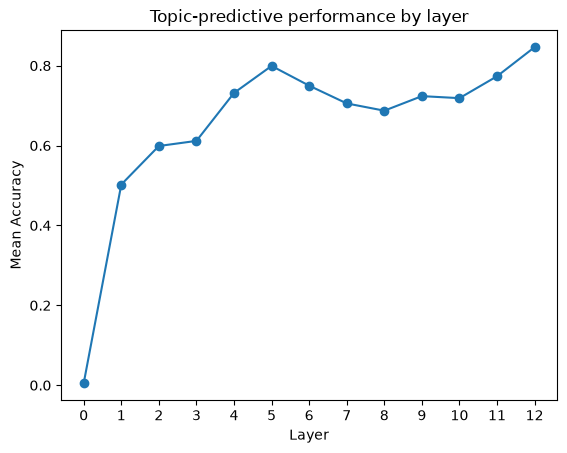

In [58]:
# Plot layer-wise R2s
plt.plot(range(13), accuracy_scores, marker='o')
plt.xlabel('Layer')
plt.ylabel('Mean Accuracy')
plt.title('Topic-predictive performance by layer')
plt.xticks(range(13))
plt.show()

As we can see, the original most predictive layer still yields a high accuracy. This is to be expected since it was the most brain predictive for the sentences, which should translate to some degree to the topics. However, we can also see from the plot that the later layers in the model now surpass the performance of layer 5. This is also to be expected if we are to go by the same logic as in question 5a. Topicality is a higher level linguistic task than sentence length. We could make a linguistic comparison here, relating early layer predictibility to "phonetic" and "phonological" tasks and later layer predictibility to "semantic" and "syntactic" tasks. 

## Your Project – Suggestions

This notebook has shown you how to work with fMRI responses from the Pereira dataset and how to assess LMs' ability to predict those responses. Hopefully, it has also sparked your curiosity and prompted new research questions, which you can develop in your own project.

In case you haven't identified any additional research question, consider the following suggestions:

* Dig deeper into the linguistic features driving brain predictivity. Other features you could explore include, e.g., sentence length measured on characters, sentence _surprisal_, or the syntactical complexity of a sentence (measured, e.g., as the depth of its dependency parser).

* Determine if the linguistic feature(s) encoded in the most brain-predictive layer are also _causally_ responsible for brain predictivity. How to do that? One common approach is to use the so-called 'residual method', developed by [Toneva et al. (2022)](https://www.nature.com/articles/s43588-022-00354-6). The idea behind this method consists in linearly removing the alleged brain-relevant information from the model embeddings and check whether brain predictivity computed from these residual embeddings decreases. If it does, it means that the ablated feature was indeed causally relevant for brain predictivity.   

* Explore different brain networks. Are there other networks that can be predicted statistically significantly? Do the most predictive model layers differ across networks?


* Try out different LMs (there are several available on 🤗HF) to determine which model/embedding "features" (e.g., size, amount of training data, training timestep, pooling strategy, learning objective, dimensionality) improve vs. harm brain predictivity.


* Analyse data from other Experiments included in the Pereira datset. Questions you may investigate include the following. Is information relevant for modelling concept- vs. sentence-level brain responses located in the same or different model layers? What is driving brain predictivity in visual areas? Are vision-language models more brain-predictive than language models when modelling data from Experiment 1?


Please note that these are just suggestions, but you are welcome to explore your own research questions. We also highly recommend that you discuss your project plans with Anna, to make sure they are feasible and sensible.

⚠️ Whichever idea you choose to explore, keep in mind that results should be computed on all participants in the Experiment you focus on, _not_ just on the example participant considered in this notebook.